In [29]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [30]:
data = pd.read_csv("Fish.csv")   
data.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [31]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 8.8 KB


In [32]:
data.describe()

,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


In [33]:
data.isnull().sum()

Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

In [34]:
data.duplicated().sum()

np.int64(0)

In [35]:
data.columns.tolist()

['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']

In [36]:
# understanding the Species column   
data['Species'].value_counts()

Species
Perch        56
Bream        35
Roach        20
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

     Species  Weight
0      Bream  610.00
1     Parkki  145.00
2      Perch  207.50
3       Pike  510.00
4      Roach  147.50
5      Smelt    9.85
6  Whitefish  423.00


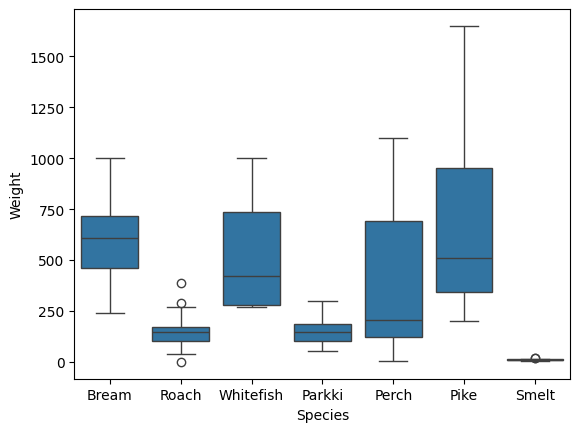

In [37]:
# understanding the realtionship between Species and the Weight    
print(
data.groupby('Species')['Weight'].median().reset_index())   
sns.boxplot(x=data.Species , y = data.Weight)  
plt.show()

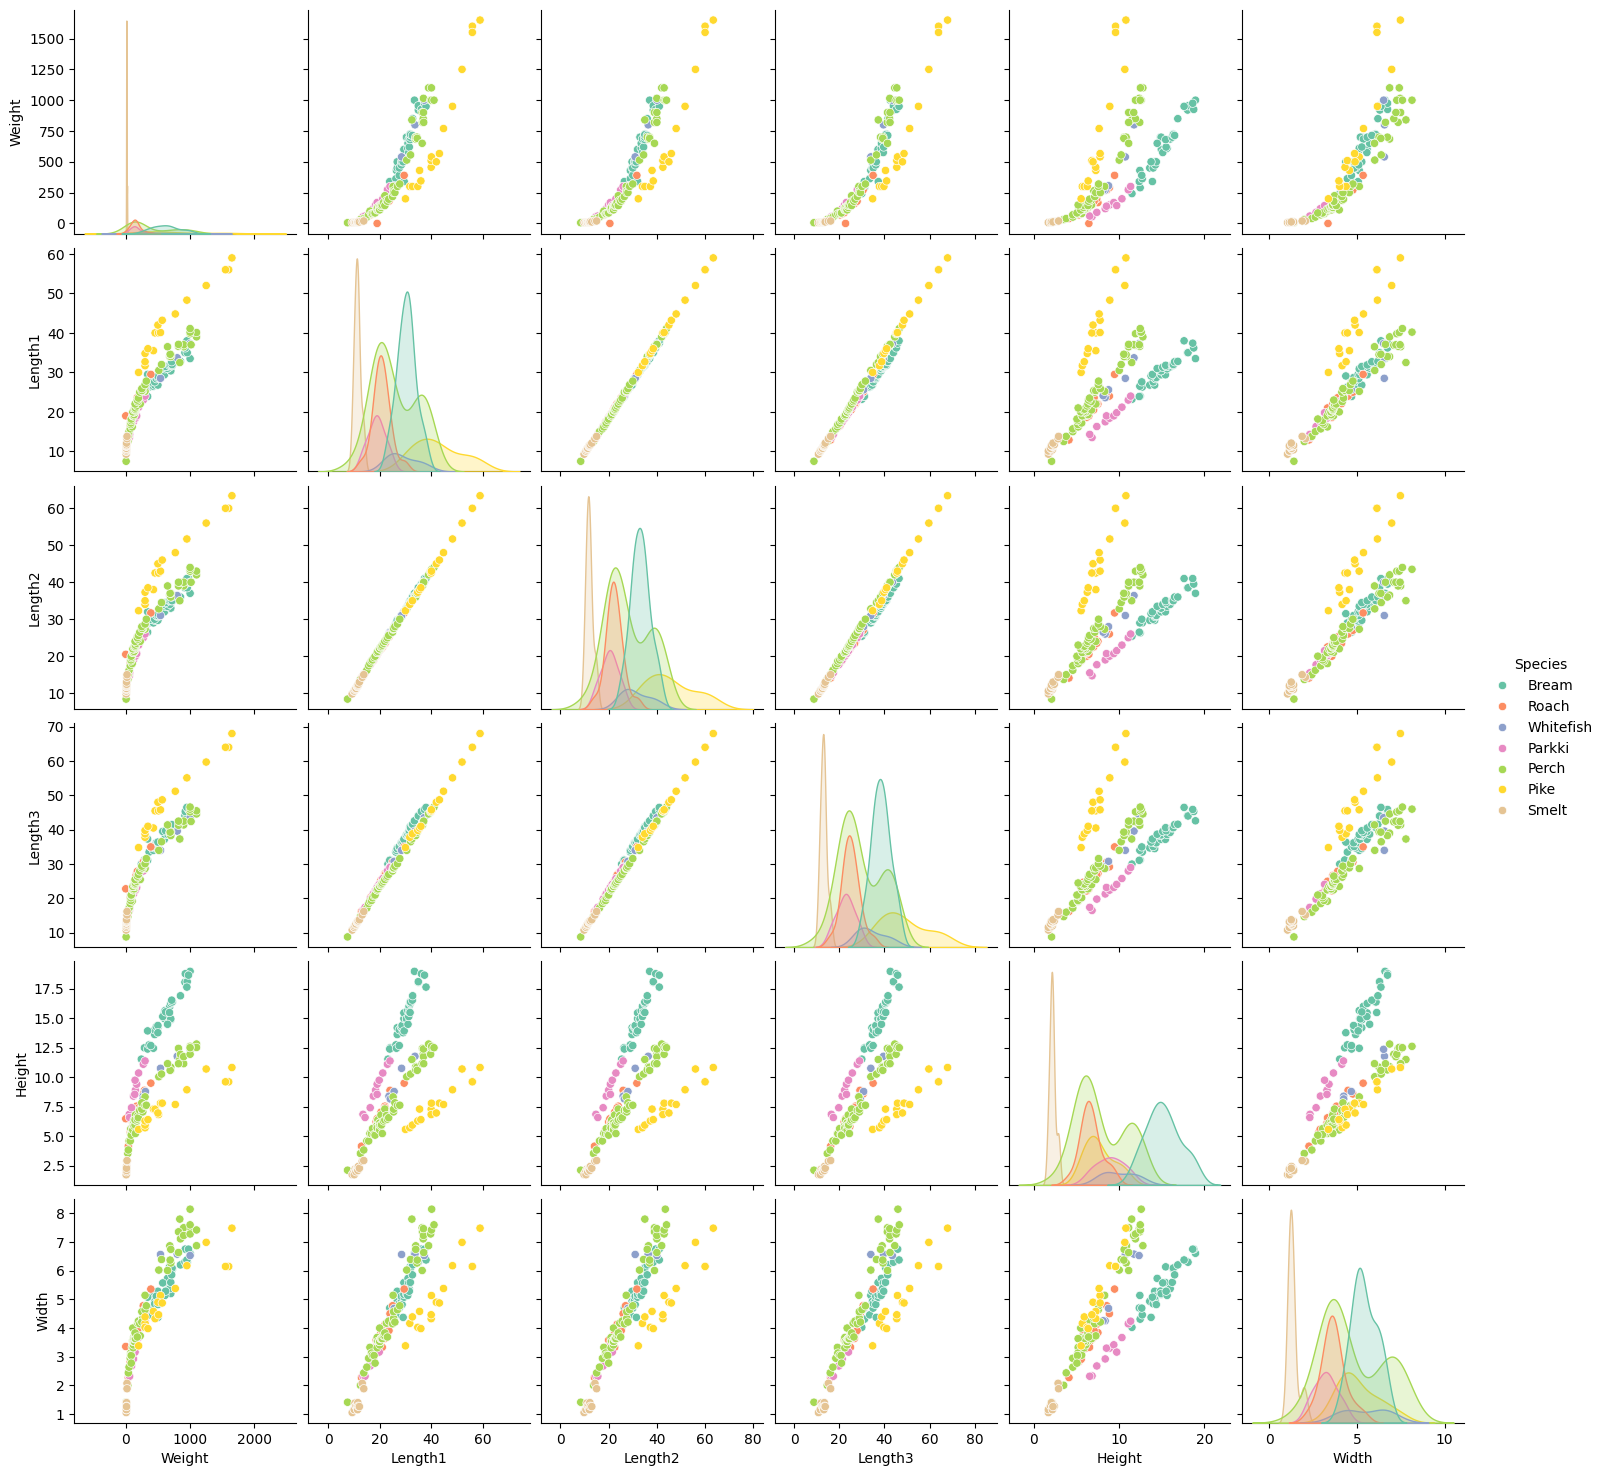

In [38]:
# instead of doing this all we need to draw the pair plot for this one 
sns.pairplot(data, hue="Species", palette="Set2")
plt.show()

In [39]:
data.head(
    
)

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [40]:
from sklearn.neighbors import KNeighborsClassifier   
from sklearn.preprocessing import StandardScaler , LabelEncoder 
from sklearn.metrics import accuracy_score , classification_report   , confusion_matrix  
from sklearn.model_selection import train_test_split 

In [41]:
le = LabelEncoder()
y = le.fit_transform(data['Species'])  
x = data.drop(columns=['Species'])  

In [42]:
X_train , X_test , Y_train , Y_test = train_test_split(x , y , test_size=0.2,random_state=42)

In [43]:
print("x train shape:",X_train.shape)  
print("y train shape:",X_test.shape)

x train shape: (127, 6)
y train shape: (32, 6)


In [44]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)   

In [45]:
# directly applying the Knn algorithm   
model = KNeighborsClassifier(metric='euclidean' , n_neighbors=3 )   
model.fit(X_train_scaled , Y_train)  
y_pred =  model.predict(X_test_scaled)    

In [46]:
model.score(X_test,Y_test)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


0.09375

In [54]:
acc = accuracy_score(Y_test , y_pred)   
cm = confusion_matrix(Y_test , y_pred)     
report = classification_report(Y_test , y_pred,labels=[0,1,2,3,4,5,6])   
print("Accuracy:", round(acc,4))  
print("\nConfusion Matrix:\n",cm)   
print("\nClassification Report:\n",report)


Accuracy: 0.8438

Confusion Matrix:
 [[10  0  0  0  0  0  0]
 [ 0  1  0  0  0  0  0]
 [ 0  0  8  0  1  0  0]
 [ 0  0  0  3  0  0  0]
 [ 0  0  1  0  0  0  0]
 [ 0  0  0  0  0  5  0]
 [ 0  0  3  0  0  0  0]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         1
           2       0.67      0.89      0.76         9
           3       1.00      1.00      1.00         3
           4       0.00      0.00      0.00         1
           5       1.00      1.00      1.00         5
           6       0.00      0.00      0.00         3

    accuracy                           0.84        32
   macro avg       0.67      0.70      0.68        32
weighted avg       0.78      0.84      0.81        32



c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

In [ ]:
data.Species.value_counts()

Species
Perch        56
Bream        35
Roach        20
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64